# GSaS regime mixture of a ticker

Download a ticker's daily prices from Yahoo, split the days into `REGIMES` regimes with a statistical jump model, fit GSaS to each regime, and plot the ticker's distribution as the weighted mixture of the regime GSaS distributions. Nothing is written to disk.

**Imports.** `yfinance` downloads the prices. `GSaS_Fit` fits one GSaS, and `GSaS_JumpRegimes` (in `gas_impl/gsas_regime.py`, which needs the `jumpmodels` package) finds the regimes and fits each of them.

In [93]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from gas_impl.gsas_fit import GSaS_Fit
from gas_impl.gsas_regime import GSaS_JumpRegimes

%config InlineBackend.figure_format = 'retina'

**Parameters.** `JUMP_PENALTY` is the cost of one regime switch: 0 lets the regimes switch freely, and larger values give fewer, longer regimes (the BMDA code uses 15 to 55).

Empirically, the bull regime should be calm with positive returns.
The bear regime should be volatile with negative returns.

In these clean cases, the bull regime sits above the LNN diagonal with lower $v_1$.
The bear regime should have higher $v_1$ than the bull regime.

In [172]:
TICKER = 'SMH'        # e.g. SPY, QQQ, SMH, TLT, GLD, ^SPGSCI 
YEARS = 20            # keep at most this many years of daily returns
REGIMES = 2       # number of regimes
JUMP_PENALTY = 100.0   # jump model lambda

# for SPY, between 50-100, the result is consistent with the global bull/bear regimes. Bear is LNN.
# for QQQ, between 100-200, we get the tech bull/bear regimes.
# for GLD, use 100 to split it into the bull/bear regimes in 2:1 ratio.

# ^SPGSCI, use 100 and 3 regimes. Commodity seems to be violently moving up and down, or else, being flat for a long time.

# bond regime is the hardest ...
# for TLT, between 150-500 (200), it is split into two volatility regimes: calm and volatile.


**Data.** This downloads the Adjusted Close, drops today's incomplete bar and computes simple daily returns, keeping the last `YEARS` years. Crypto trades every day, so for a `-USD` symbol the returns are taken close-to-close on weekdays only.

In [173]:
START_DATE = None # pd.to_datetime('2020-07-31')
END_DATE = None # pd.to_datetime('2020-07-31')


px = yf.download(TICKER, period='max', auto_adjust=False, progress=False)['Adj Close']
if isinstance(px, pd.DataFrame):                  # yfinance returns one column per ticker
    px = px.iloc[:, 0]
px = px.dropna()
px = px[px.index.normalize() < pd.Timestamp.today().normalize()]
if START_DATE is not None:
    px = px.loc[START_DATE:]  
if END_DATE is not None:
    px = px.loc[:END_DATE]        
if TICKER.endswith('-USD'):
    px = px[px.index.dayofweek < 5]
xs = px.pct_change().dropna()
xs = xs.loc[xs.index[-1] - pd.DateOffset(years=YEARS):]
px = px.loc[xs.index]


print(f"{TICKER}: {len(xs)} daily returns, {xs.index[0].date()} .. {xs.index[-1].date()}")

SMH: 5031 daily returns, 2006-11-24 .. 2026-11-24


**Single GSaS fit.** One GSaS for all days, as the reference the regime mixture is compared with.

In [174]:
FIT = GSaS_Fit(xs.values)
assert FIT.status == 'ok', f"{TICKER}: {FIT.status}"
print(FIT.summary().drop(['winsor_pct', 'status']).to_string(float_format=lambda v: f'{v:.4f}'))

n           5031
exkurt    5.2498
SPD       0.5577
v1        0.2529
v2        0.2233
skew     -0.0384
alpha     0.2682
k        15.8143
xi        0.0675


**Regimes and weights.** The jump model labels every day with a regime. Its features are the ticker's EWM return, log EWM downside deviation and EWM Sortino ratio at halflives of 1, 5, 10 and 21 days, each clipped to its mean ± 3 sd and standardized. It chooses the labels $s_t$ and one feature centroid $\theta_j$ per regime to minimize

$$\sum_t \tfrac12\,\lVert y_t-\theta_{s_t}\rVert^2 \;+\; \lambda\,\#\{t: s_t\ne s_{t-1}\},$$

the distance of each day's features $y_t$ from its regime's centroid, plus `JUMP_PENALTY` $\lambda$ for every switch. It alternates two exact steps until the objective stops falling: the best labels given the centroids (dynamic programming), then each centroid as the mean of its regime's features. It keeps the best of 10 starts.

The **weight** of regime $j$ is its share of days, $w_j = \#\{t: s_t=j\}/n$, and its GSaS is `GSaS_Fit` on the returns of its days. A regime whose shape lies outside the GSaS region is drawn as a normal (`drawn_as`). Regimes are numbered from calm to turbulent. The transition matrix shows how often each regime is followed by each other one.

In [175]:
REG = GSaS_JumpRegimes(xs, n_regimes=REGIMES, jump_penalty=JUMP_PENALTY).fit()
SUM = REG.summary()
print(SUM.to_string(float_format=lambda v: f'{v:.4f}'))
print()
print(REG.transition_matrix().to_string(float_format=lambda v: f'{v:.4f}'))

        weight  days  runs  mean_run    mean     sd   skew  exkurt    SPD     v1     v2  alpha        k     xi status drawn_as
regime                                                                                                                        
1       0.7024  3534    13  271.8462  0.0019 0.0149 0.0565  2.5484 0.5018 0.1537 0.1529 0.0203 319.6186 0.0031     ok     GSaS
2       0.2976  1497    14  106.9286 -0.0016 0.0275 0.1231  2.9853 0.4638 0.1727 0.1004 1.0800   5.5890 0.2179     ok     GSaS

to        1      2
from              
1    0.9963 0.0037
2    0.0087 0.9913


**Regimes over time.** The price (log scale) on a background shaded by regime, and the daily returns coloured by regime.

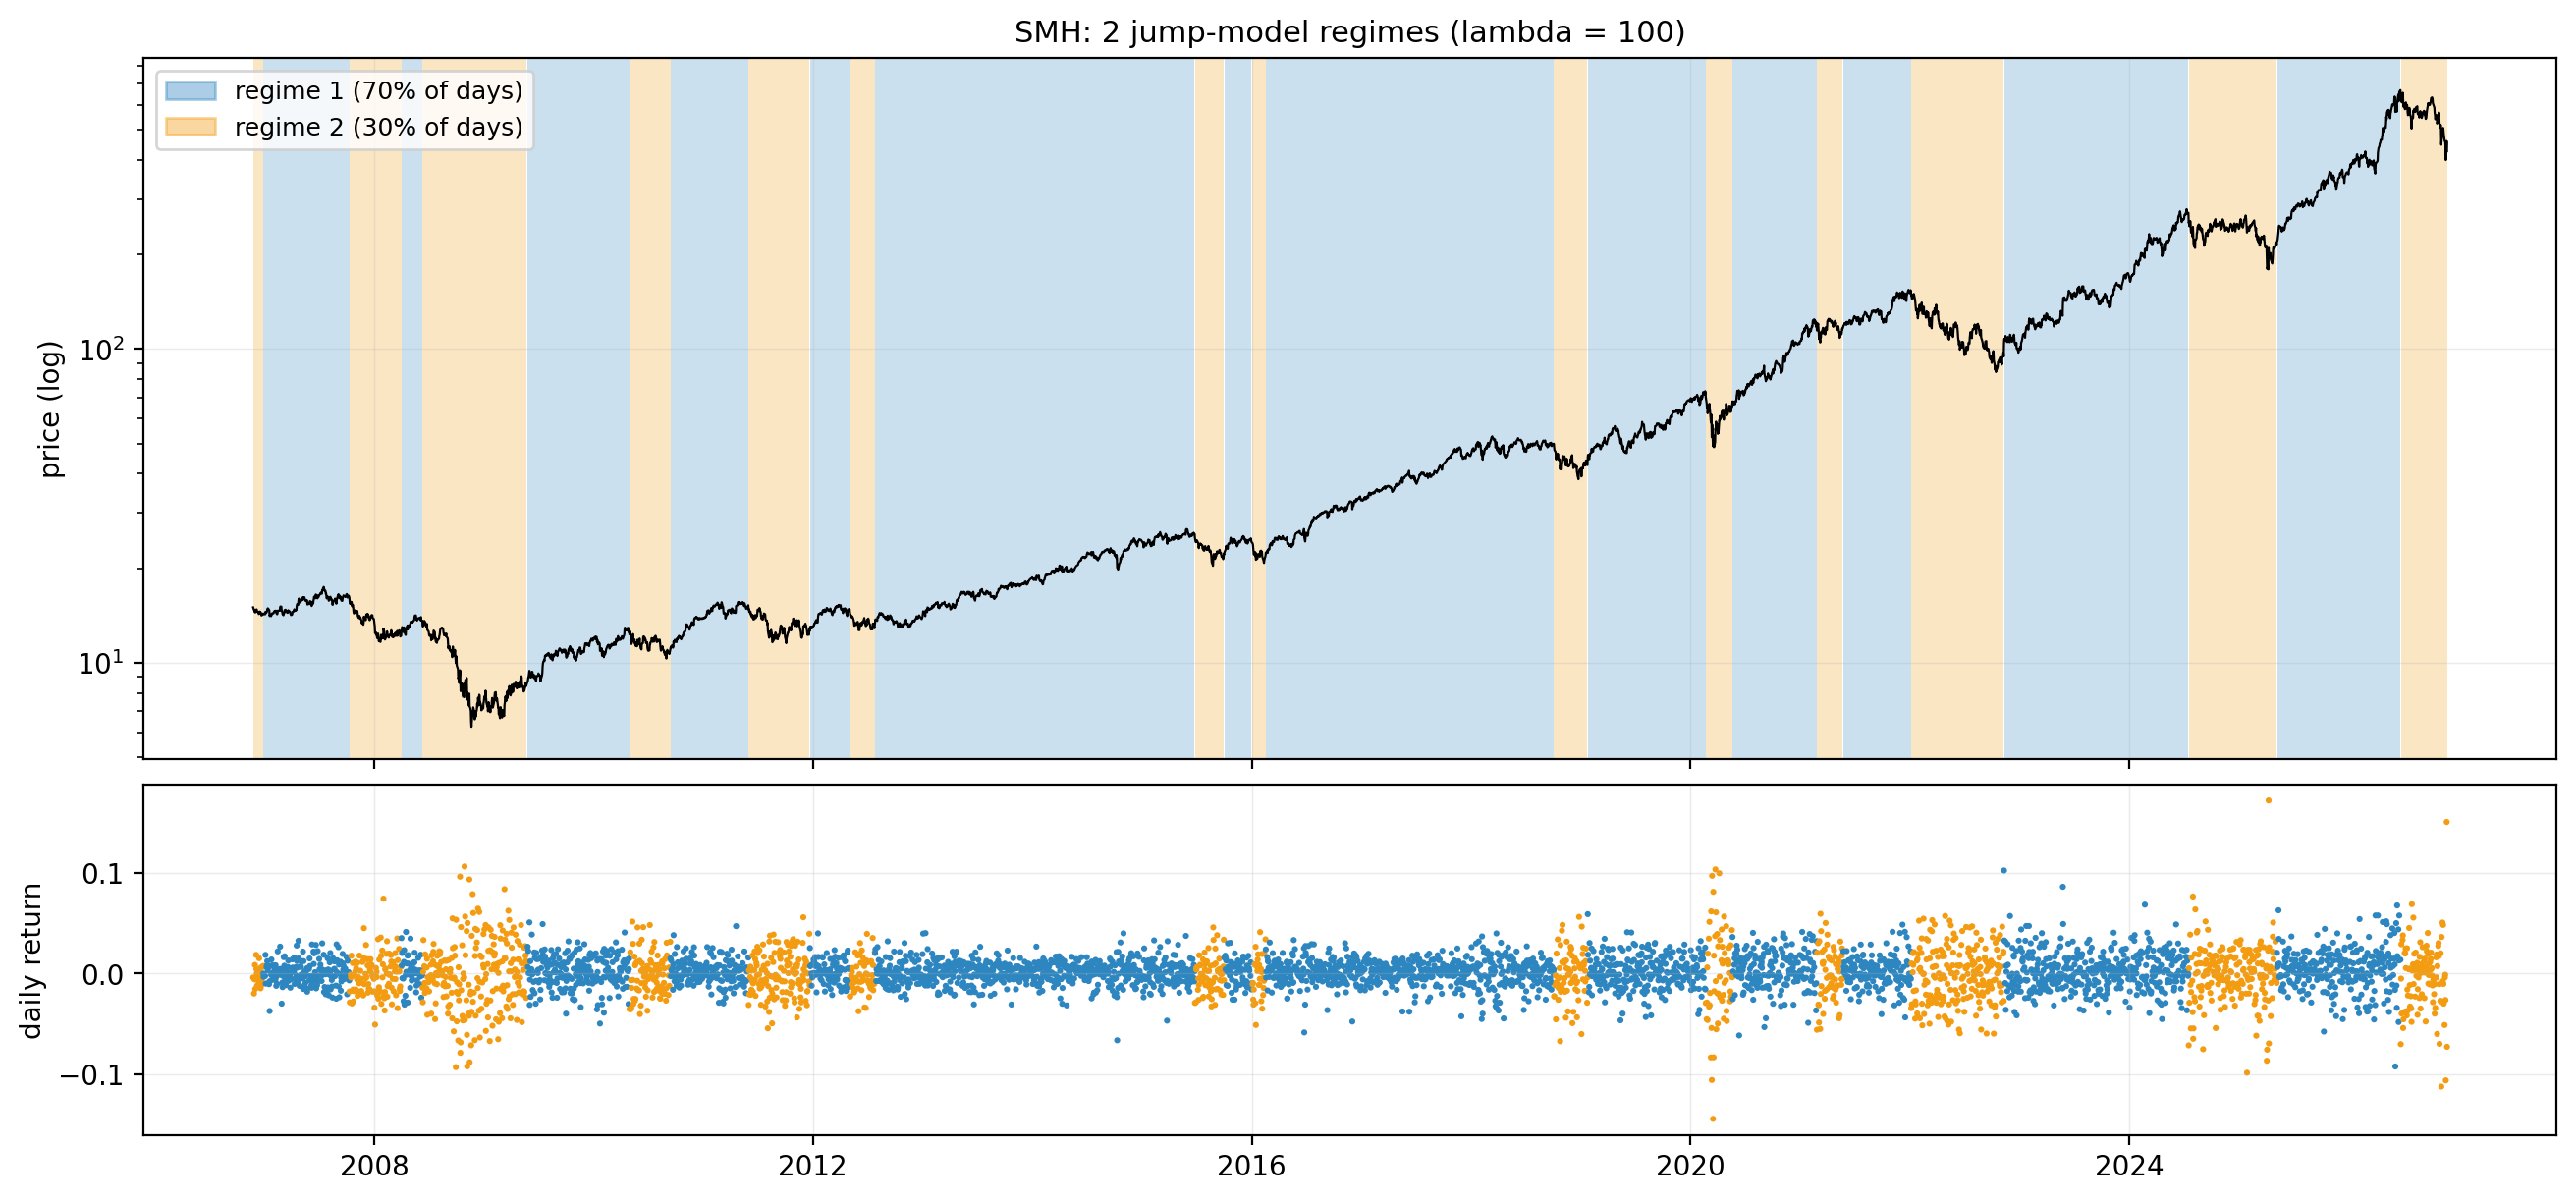

In [176]:
COLORS = ['#2e86c1', '#f39c12', '#c0392b', '#27ae60', '#8e44ad', '#7f8c8d']
col = {j: COLORS[(j - 1) % len(COLORS)] for j in range(1, REGIMES + 1)}

fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True, constrained_layout=True, height_ratios=[2, 1])
ax = axes[0]
ax.plot(px.index, px.values, color='black', lw=0.8)
ax.set_yscale('log'); ax.set_ylabel('price (log)')
for run in REG.runs().itertuples():
    ax.axvspan(run.start, run.end, color=col[run.regime], alpha=0.25, lw=0)
for j in range(1, REGIMES + 1):
    ax.fill_between([], [], color=col[j], alpha=0.4, label=f'regime {j} ({SUM.weight[j]:.0%} of days)')
ax.legend(loc='upper left', fontsize=9); ax.grid(alpha=0.25, lw=0.5)
ax.set_title(f'{TICKER}: {REGIMES} jump-model regimes (lambda = {JUMP_PENALTY:g})', fontsize=11)
ax = axes[1]
ax.scatter(xs.index, xs.values, c=[col[j] for j in REG.labels], s=1.5)
ax.set_ylabel('daily return'); ax.grid(alpha=0.25, lw=0.5)
plt.show()

**Distribution and Q-Q.** The histogram of all returns with the regime mixture $\sum_j w_j f_j$ (solid), each weighted regime $w_j f_j$ (dashed) and the single GSaS fit (dotted), on linear and log scales. The Q-Q plot compares the data quantiles with the mixture's and the single fit's.

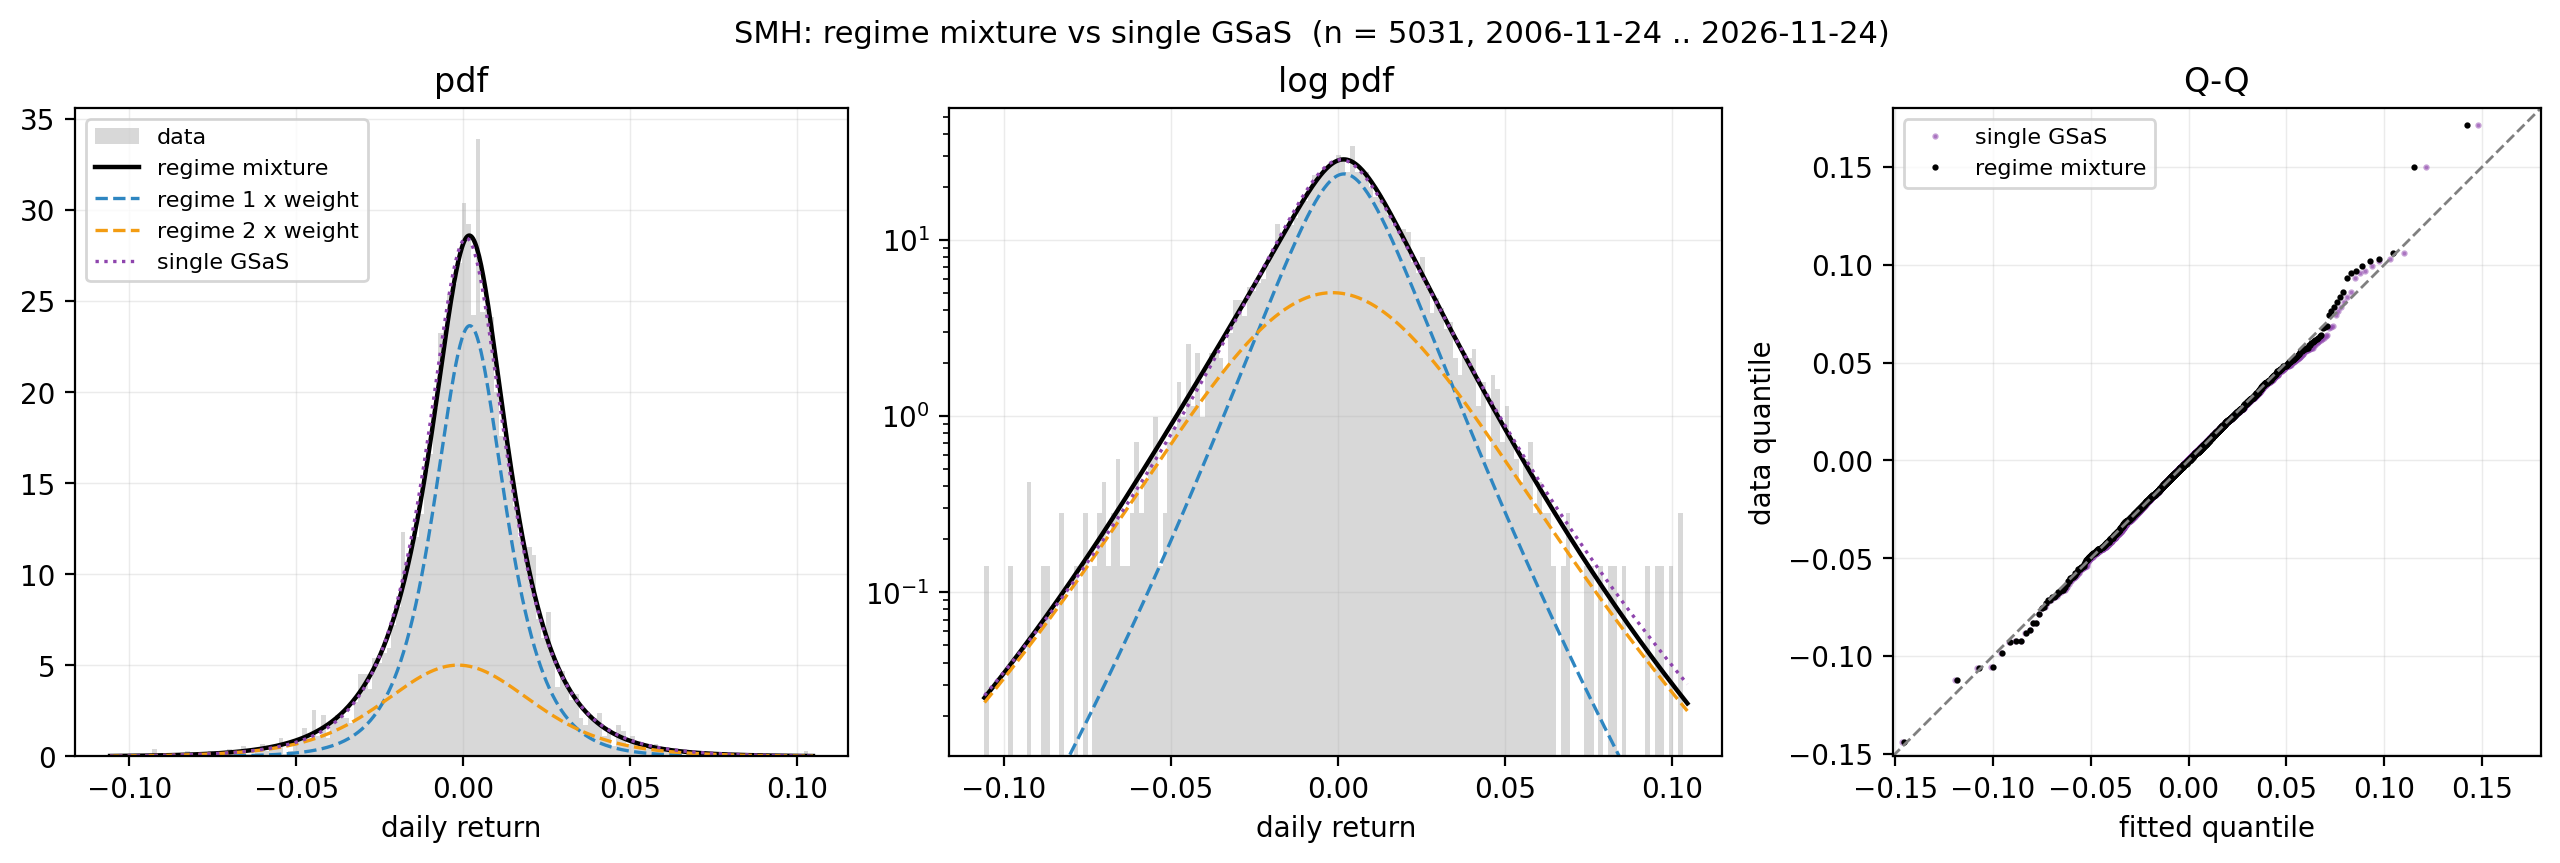

In [177]:
x = xs.values
lo, hi = np.percentile(x, [0.05, 99.95])
grid = np.linspace(lo, hi, 700)
comp = REG.component_pdfs(grid)
mix_pdf = comp.sum(axis=1)
q_mix, x_sorted = REG.qq()
q_one, _ = FIT.qq()
lim = [x_sorted[0]*1.05, x_sorted[-1]*1.05]

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), constrained_layout=True)
for a in axes[:2]:
    a.hist(x, bins=150, range=(lo, hi), density=True, color='grey', alpha=0.30, label='data')
    a.plot(grid, mix_pdf, color='black', lw=1.6, label='regime mixture')
    for j in range(REGIMES):
        a.plot(grid, comp[:, j], color=col[j + 1], lw=1.2, ls='--', label=f'regime {j + 1} x weight')
    a.plot(grid, FIT.pdf(grid), color='#8e44ad', lw=1.2, ls=':', label='single GSaS')
    a.set_xlabel('daily return'); a.grid(alpha=0.25, lw=0.5); a.locator_params(axis='x', nbins=5)
axes[0].set_title('pdf'); axes[0].legend(fontsize=8, loc='upper left')
axes[1].set_title('log pdf'); axes[1].set_yscale('log'); axes[1].set_ylim(max(1e-2, 0.5*mix_pdf.min()), None)
a = axes[2]
a.plot(q_one, x_sorted, '.', ms=2.5, color='#8e44ad', alpha=0.5, label='single GSaS')
a.plot(q_mix, x_sorted, '.', ms=2.5, color='black', label='regime mixture')
a.plot(lim, lim, color='grey', lw=1, ls='--')
a.set_xlim(lim); a.set_ylim(lim); a.set_aspect('equal'); a.grid(alpha=0.25, lw=0.5); a.legend(fontsize=8)
a.set_xlabel('fitted quantile'); a.set_ylabel('data quantile'); a.set_title('Q-Q')
fig.suptitle(f'{TICKER}: regime mixture vs single GSaS  (n = {len(x)}, {xs.index[0].date()} .. {xs.index[-1].date()})',
             fontsize=11)
plt.show()

**Plane.** Each regime's sample shape $(v_1, v_2)$ is a circle sized by its weight, and the single fit is the black square. The reference lines are the LNN diagonal and curves of fixed $k$ (solid for $k>0$, dashed for $k<0$). A regime below $v_2 = 0$ or outside the curves is outside the GSaS region, and is drawn as a normal.

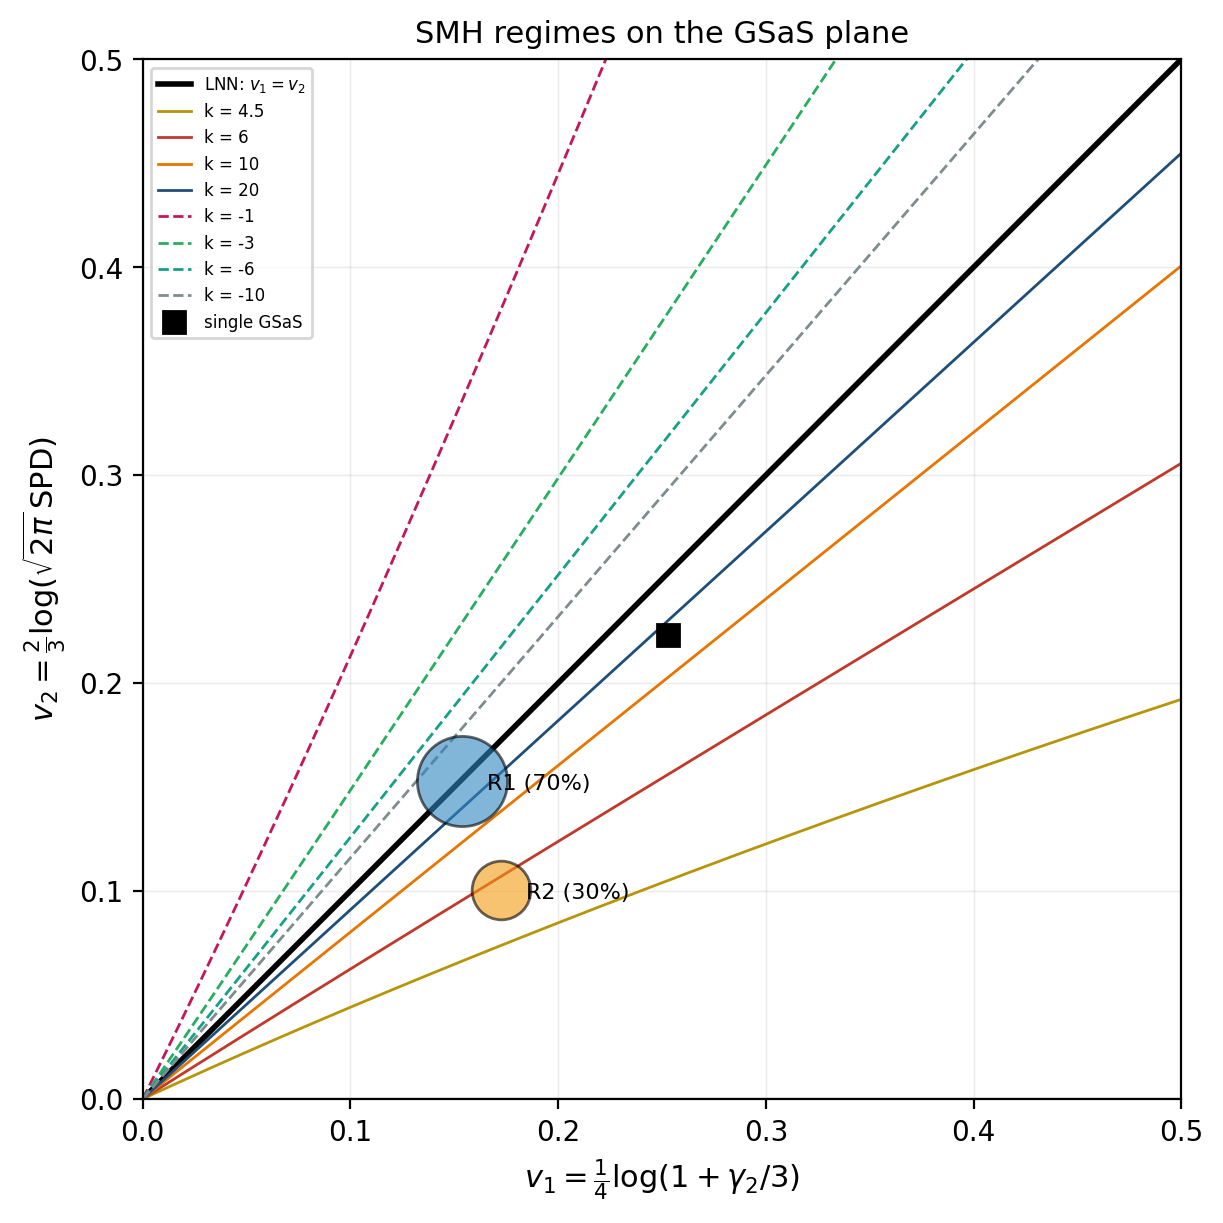

In [178]:
pts = [(FIT.shape['v1'], FIT.shape['v2'])] + list(zip(SUM.v1, SUM.v2))
V_MAX = max(0.5, np.ceil(1.15*np.nanmax(np.abs(pts))*10)/10)
K_CURVES = [(4.5, '#b7950b'), (6, '#c0392b'), (10, '#E77500'), (20, '#1f4e79'),
            (-1.0, '#c2185b'), (-3.0, '#27ae60'), (-6.0, '#16a085'), (-10.0, '#7f8c8d')]

fig, ax = plt.subplots(figsize=(6, 6), constrained_layout=True)
vg = np.linspace(0, V_MAX, 201)
ax.plot(vg, vg, color='black', lw=2.0, label=r'LNN: $v_1=v_2$')
for k, c in K_CURVES:
    v1c, v2c = GSaS_Fit.plane_k_curve(k, V_MAX)
    ax.plot(v1c, v2c, color=c, lw=1.0, ls='-' if k > 0 else '--', label=f'k = {k:g}')
ax.plot(*pts[0], 's', color='black', ms=8, zorder=4, label='single GSaS')
for j in range(1, REGIMES + 1):
    r = SUM.loc[j]
    ax.scatter(r.v1, r.v2, s=1500*r.weight, color=col[j], alpha=0.6, edgecolor='black', zorder=3)
    ax.annotate(f"R{j} ({r.weight:.0%})" + ('' if r.drawn_as == 'GSaS' else ', normal'), (r.v1, r.v2),
                textcoords='offset points', xytext=(9, -3), fontsize=8)
ax.axhline(0, color='grey', lw=0.8)
ax.set_xlabel(r'$v_1 = \frac{1}{4}\log(1 + \gamma_2/3)$', fontsize=11)
ax.set_ylabel(r'$v_2 = \frac{2}{3}\log(\sqrt{2\pi}\,\mathrm{SPD})$', fontsize=11)
ax.set_xlim(0, V_MAX); ax.set_ylim(min(0, np.nanmin(SUM.v2) - 0.05), V_MAX); ax.grid(alpha=0.25, lw=0.5)
ax.legend(fontsize=6, loc='upper left'); ax.set_title(f'{TICKER} regimes on the GSaS plane', fontsize=11)
plt.show()